# A transparent adaptation comparison

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/22-capstone.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/22-capstone.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `6de869305e443830976c333b894505e11ac63c103c94c7c484905febbf89d0ab`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# A transparent adaptation comparison

**Lesson 22 · Original synthetic data · Independent educational project**

## Objectives

Combine ensemble summaries, threshold exposure and a decision table; state limits.

[Previous](21-reproducibility.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/22-capstone.ipynb) · [Next](23-dte-workflows.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=22-capstone.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

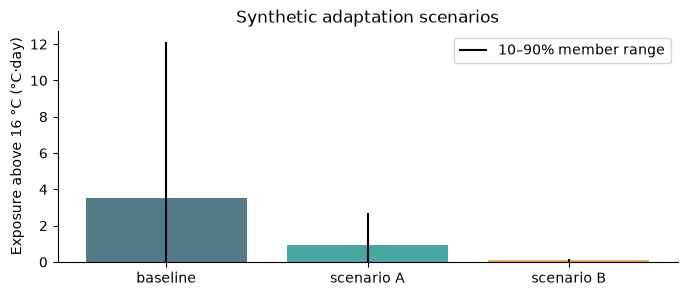

            mean_degree_days  p10    p90  illustrative_cost
scenario                                                   
baseline                3.54  0.0  12.12                0.0
scenario A              0.91  0.0   2.71                1.0
scenario B              0.10  0.0   0.17                2.5


In [2]:
import pandas as pd
members = lab.ensemble(seed=21, members=40)
threshold = 16
rows = []
for label, cooling, cost in [("baseline", 0., 0.), ("scenario A", .5, 1.), ("scenario B", 1., 2.5)]:
    exposure = np.maximum(members-cooling-threshold, 0).sum(axis=1)
    rows.append({"scenario": label, "mean_degree_days": exposure.mean(),
                 "p10": np.quantile(exposure, .1), "p90": np.quantile(exposure, .9), "illustrative_cost": cost})
table = pd.DataFrame(rows).set_index("scenario")
assert np.all(np.diff(table.mean_degree_days) <= 0)
assert np.all(table.p10 <= table.p90)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(table.index, table.mean_degree_days, color=["#557b8a", "#49a9a0", "#e4ac54"])
ax.vlines(np.arange(3), table.p10, table.p90, color="black", label="10–90% member range")
ax.set(ylabel="Exposure above 16 °C (°C·day)", title="Synthetic adaptation scenarios")
ax.legend(); plt.show()
print(table.round(2).to_string())

## Exercise

Add a third scenario and a different threshold. Write a short recommendation that explains assumptions, uncertainty, provenance and missing impact information.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

The costs are arbitrary units and cooling is imposed uniformly. This comparison teaches transparent assumptions; it cannot select a real investment or substitute for locally validated impact models.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/climate-digital-twin/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).